<a href="https://colab.research.google.com/github/nabeel-khundmiri/Codveda-ML-Level-1/blob/main/Telco_Customer_Churn_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telecom Customer Churn Prediction Using KNN

## Codveda Technology — Machine Learning Internship

### Level 1: Task 1 & Task 3

**Task 1:** Data Preprocessing for Machine Learning  
**Task 3:** K-Nearest Neighbors (KNN) Classifier

### Business Problem

Customer churn is a major challenge for telecommunications companies.
The objective of this project is to preprocess customer data and develop
a KNN classification model that predicts whether a customer is likely to
churn based on their demographic, service, and account information.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Import Libraries -

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
file_path = "/content/drive/MyDrive/Codveda_ML_Level_1/data/raw/Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully!
Rows: 7043
Columns: 21


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [ ]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df.shape


(7043, 21)

In [ ]:
df["PaymentMethod"].value_counts()

,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


##  Understanding the Dataset

The dataset contains customer demographic, service, and account
information. The target variable is `Churn`, which indicates whether
a customer has left the telecom service.

Before preprocessing, we identify the feature columns, target variable,
data types, and columns that should not be used for prediction.

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df["TotalCharges"].head(20)


,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
5,820.5
6,1949.4
7,301.9
8,3046.05
9,3487.95


In [ ]:
df["TotalCharges"].dtype

dtype('O')

In [ ]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [ ]:
df["TotalCharges"].dtype

dtype('float64')

In [ ]:
df["PaymentMethod"].dtype

dtype('O')

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
df[df["TotalCharges"].isnull()][
    ["tenure", "TotalCharges", "MonthlyCharges", "Churn"]
]

,tenure,TotalCharges,MonthlyCharges,Churn
488,0,NaN,52.55,No
753,0,NaN,20.25,No
936,0,NaN,80.85,No
1082,0,NaN,25.75,No
1340,0,NaN,56.05,No
3331,0,NaN,19.85,No
3826,0,NaN,25.35,No
4380,0,NaN,20.00,No
5218,0,NaN,19.70,No
6670,0,NaN,73.35,No


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


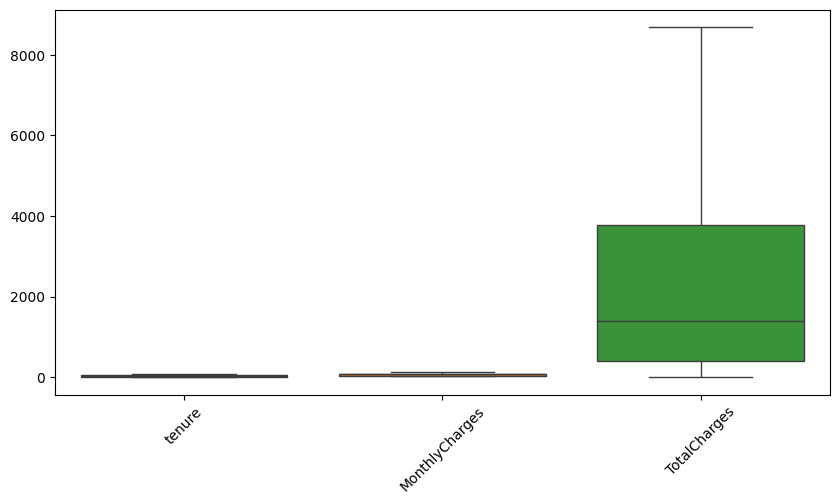

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["tenure", "MonthlyCharges", "TotalCharges"]])
plt.xticks(rotation=45)
plt.show()

##      Feature and Target Separation

The target variable is `Churn`, which indicates whether a customer
left the telecom service.

All relevant customer demographic, service, and account attributes
will be used as input features.

In [ ]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


##Train-Test Split

The dataset is divided into training and testing subsets.
The training data will be used to learn the preprocessing parameters
and train the KNN model, while the test data will be reserved for
final evaluation on unseen observations.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [ ]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [ ]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))


Training target distribution:
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64


In [ ]:
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Testing target distribution:
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


## Identify Numerical and Categorical Features

Numerical features contain quantitative values that can be used
directly after scaling.

Categorical features contain labels or categories and must be
encoded into numerical representations before being provided
to the KNN classifier.

In [ ]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


## Combine Preprocessing Steps

The numerical and categorical preprocessing pipelines are combined
using ColumnTransformer so that each type of feature receives the
appropriate preprocessing operations.

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

Original training shape: (5634, 19)
Processed training shape: (5634, 45)
Original test shape: (1409, 19)
Processed test shape: (1409, 45)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

for i, name in enumerate(feature_names):
    print(i + 1, name)

1 num__SeniorCitizen
2 num__tenure
3 num__MonthlyCharges
4 num__TotalCharges
5 cat__gender_Female
6 cat__gender_Male
7 cat__Partner_No
8 cat__Partner_Yes
9 cat__Dependents_No
10 cat__Dependents_Yes
11 cat__PhoneService_No
12 cat__PhoneService_Yes
13 cat__MultipleLines_No
14 cat__MultipleLines_No phone service
15 cat__MultipleLines_Yes
16 cat__InternetService_DSL
17 cat__InternetService_Fiber optic
18 cat__InternetService_No
19 cat__OnlineSecurity_No
20 cat__OnlineSecurity_No internet service
21 cat__OnlineSecurity_Yes
22 cat__OnlineBackup_No
23 cat__OnlineBackup_No internet service
24 cat__OnlineBackup_Yes
25 cat__DeviceProtection_No
26 cat__DeviceProtection_No internet service
27 cat__DeviceProtection_Yes
28 cat__TechSupport_No
29 cat__TechSupport_No internet service
30 cat__TechSupport_Yes
31 cat__StreamingTV_No
32 cat__StreamingTV_No internet service
33 cat__StreamingTV_Yes
34 cat__StreamingMovies_No
35 cat__StreamingMovies_No internet service
36 cat__StreamingMovies_Yes
37 cat__Con

In [ ]:
processed_df = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

processed_df.head()

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
3738,-0.441773,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.441773,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.441773,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.441773,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,-0.441773,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## "TASK 1" COMPLETED


# ==================================================

# TASK 3: KNN CLASSIFIER
# ==================================================

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. TRAIN A BASELINE KNN MODEL (K = 5)
# ------------------------------------------------------------

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_processed, y_train)
print("BASELINE KNN MODEL TRAINED")

BASELINE KNN MODEL TRAINED


# ------------------------------------------------------------
# 2. MAKE PREDICTIONS ON THE TEST DATA
# ------------------------------------------------------------

In [ ]:
y_pred = knn.predict(X_test_processed)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
)
print("\nBASELINE MODEL PERFORMANCE (K = 5)")
print("-" * 40)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


BASELINE MODEL PERFORMANCE (K = 5)
----------------------------------------
Accuracy : 0.7637 (76.37%)
Precision: 0.5527
Recall   : 0.5749
F1-score : 0.5636


# 3. CONFUSION MATRIX and CLASSIFICATION REPORT


CONFUSION MATRIX
----------------------------------------
Rows = Actual labels; Columns = Predicted labels
            Predicted No  Predicted Yes
Actual No            861            174
Actual Yes           159            215


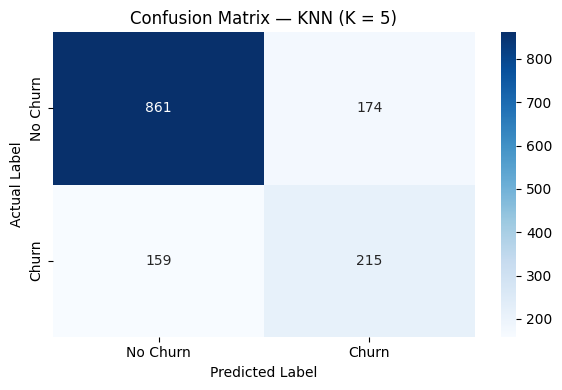


CLASSIFICATION REPORT
----------------------------------------
              precision    recall  f1-score   support

    No Churn       0.84      0.83      0.84      1035
       Churn       0.55      0.57      0.56       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.76      0.77      1409



In [ ]:
cm = confusion_matrix(
    y_test, y_pred, labels=["No", "Yes"]
)

print("\nCONFUSION MATRIX")
print("-" * 40)
print("Rows = Actual labels; Columns = Predicted labels")
print(pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix — KNN (K = 5)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("\nCLASSIFICATION REPORT")
print("-" * 40)

print(classification_report(
    y_test,
    y_pred,
    labels=["No", "Yes"],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# 5. COMPARE DIFFERENT VALUES OF K

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

results = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            pos_label="Yes", zero_division=0
        )
    })
results_df = pd.DataFrame(results)

print("\nCOMPARISON OF DIFFERENT K VALUES")
print("-" * 60)
print(results_df.round(4).to_string(index=False))


COMPARISON OF DIFFERENT K VALUES
------------------------------------------------------------
 K  Accuracy  Precision  Recall  F1-score
 1    0.7339     0.4987  0.5134    0.5059
 3    0.7537     0.5349  0.5535    0.5440
 5    0.7637     0.5527  0.5749    0.5636
 7    0.7644     0.5544  0.5722    0.5632
 9    0.7793     0.5840  0.5856    0.5848
11    0.7779     0.5822  0.5775    0.5799
15    0.7779     0.5845  0.5642    0.5741
21    0.7814     0.5907  0.5749    0.5827


#6. VISUALIZE PERFORMANCE FOR DIFFERENT K VALUES

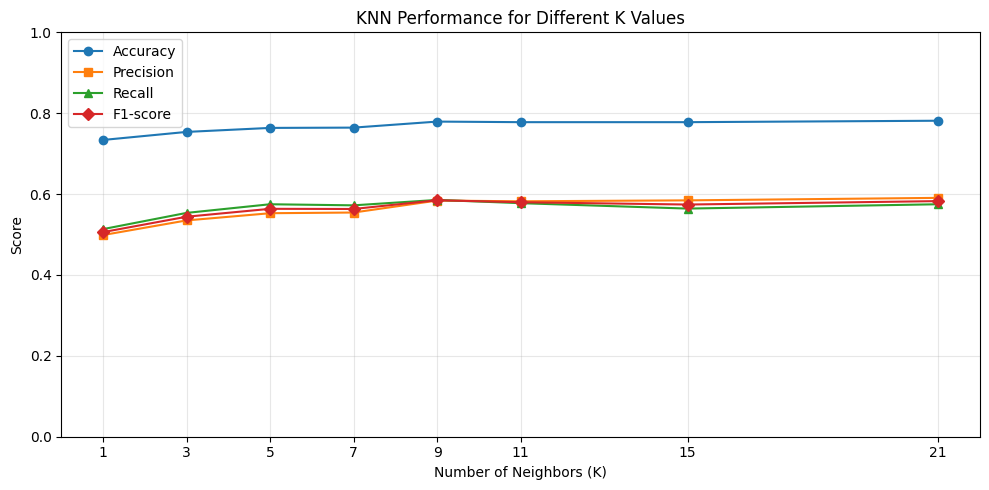

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["K"],
    results_df["Precision"],
    marker="s",
    label="Precision"
)

plt.plot(
    results_df["K"],
    results_df["Recall"],
    marker="^",
    label="Recall"
)

plt.plot(
    results_df["K"],
    results_df["F1-score"],
    marker="D",
    label="F1-score"
)

plt.title("KNN Performance for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.xticks(k_values)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 7. IDENTIFY THE BEST RESULT BY F1-SCORE

In [ ]:
best_row = results_df.loc[results_df["F1-score"].idxmax()]

print("\nBEST RESULT IN THIS K COMPARISON")
print("-" * 40)
print(f"Best K by F1-score: {int(best_row['K'])}")
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print(f"F1-score : {best_row['F1-score']:.4f}")

print("\nEvaluation completed successfully.")



BEST RESULT IN THIS K COMPARISON
----------------------------------------
Best K by F1-score: 9
Accuracy : 0.7793
Precision: 0.5840
Recall   : 0.5856
F1-score : 0.5848

Evaluation completed successfully.


##TASK 3- K MEANS CLUSTERING(INTERMEDIATE)

In [62]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Reuse the existing preprocessing pipeline.
# It was fitted on training data without using the Churn target.
X_cluster_processed = preprocessor.transform(X)

print("Clustering data shape:", X_cluster_processed.shape)
print("Number of customers:", X_cluster_processed.shape[0])
print("Number of clustering features:", X_cluster_processed.shape[1])


Clustering data shape: (7043, 45)
Number of customers: 7043
Number of clustering features: 45


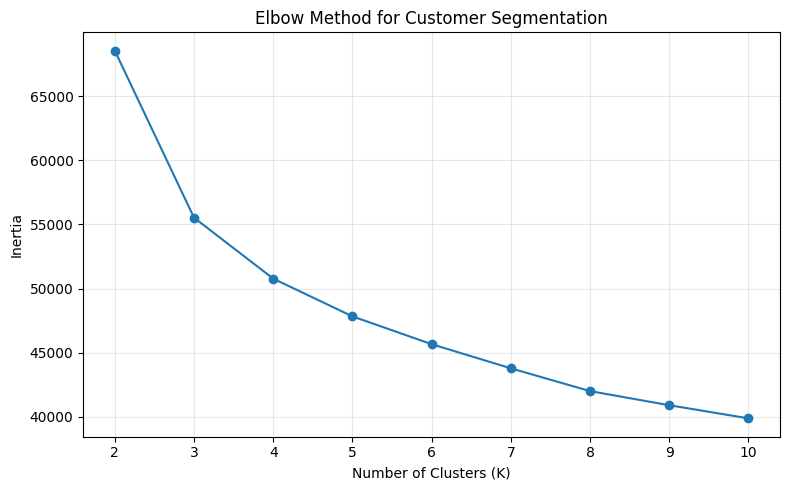

In [63]:

k_values = range(2, 11)
inertia_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_cluster_processed)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [64]:

chosen_k = 4  # Change this based on your elbow plot

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster_processed)

# Store each customer's assigned cluster
clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("K-Means model trained.")
print("\nCustomers per cluster:")
print(clustered_df["Cluster"].value_counts().sort_index())

print("\nCluster proportions (%):")
print(
    (clustered_df["Cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


K-Means model trained.

Customers per cluster:
Cluster
0    1976
1    2621
2    1526
3     920
Name: count, dtype: int64

Cluster proportions (%):
Cluster
0    28.06
1    37.21
2    21.67
3    13.06
Name: proportion, dtype: float64


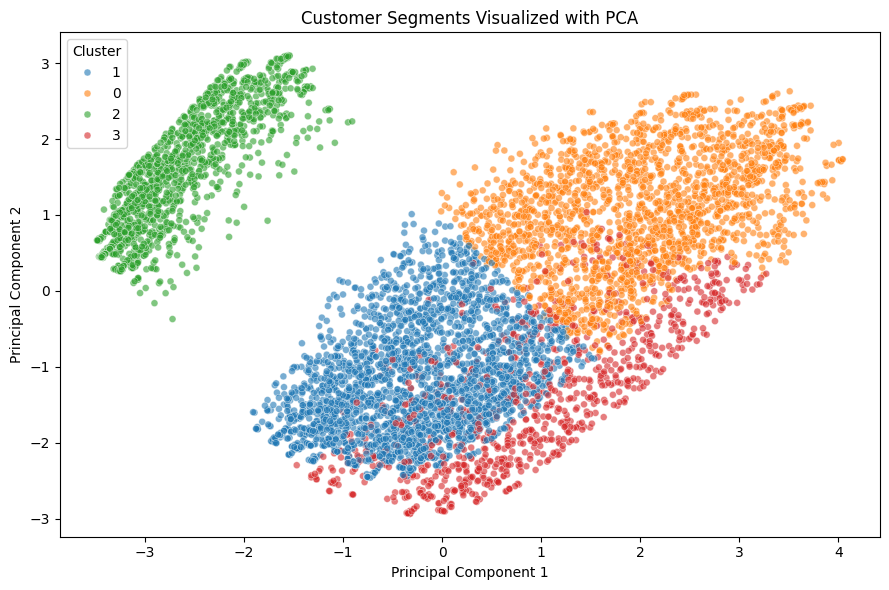

Variance represented by two components: 45.28%


In [65]:

# Convert the processed matrix to dense form for PCA.
# This dataset is small enough for this conversion.
X_dense = (
    X_cluster_processed.toarray()
    if hasattr(X_cluster_processed, "toarray")
    else X_cluster_processed
)

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_dense)

plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=25
)

plt.title("Customer Segments Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance represented by two components:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


AVERAGE CUSTOMER PROFILE BY CLUSTER
         tenure  MonthlyCharges  TotalCharges
Cluster                                      
0         58.60           89.35       5237.30
1         15.68           66.51       1019.73
2         30.55           21.08        662.60
3         26.62           79.40       2199.37

CHURN DISTRIBUTION WITHIN EACH CLUSTER (%)
Churn       No    Yes
Cluster              
0        86.94  13.06
1        59.98  40.02
2        92.60   7.40
3        51.20  48.80


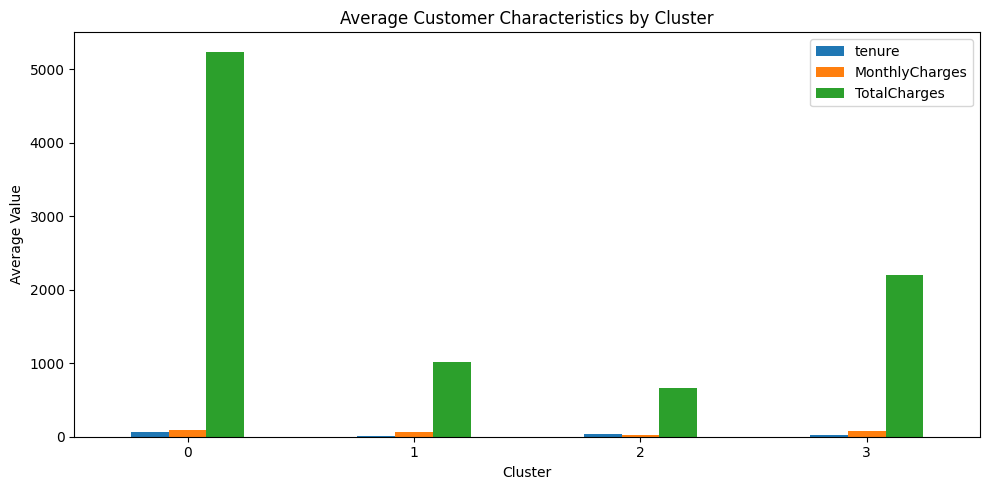

In [66]:

# Numerical customer profiles
numeric_profile = clustered_df.groupby("Cluster")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

print("AVERAGE CUSTOMER PROFILE BY CLUSTER")
print(numeric_profile)

# Churn rate within each cluster, for interpretation only
churn_profile = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Churn"],
    normalize="index"
).mul(100).round(2)

print("\nCHURN DISTRIBUTION WITHIN EACH CLUSTER (%)")
print(churn_profile)

# Visualize numerical differences between clusters
numeric_profile.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Customer Characteristics by Cluster")
plt.ylabel("Average Value")
plt.xlabel("Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [67]:

results_dir = (
    "/content/drive/MyDrive/Codveda_ML_Level_1/results"
)
os.makedirs(results_dir, exist_ok=True)

elbow_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values
})

elbow_df.to_csv(
    os.path.join(results_dir, "intermediate_task3_kmeans_elbow.csv"),
    index=False
)

clustered_df.to_csv(
    os.path.join(results_dir, "intermediate_task3_customer_clusters.csv"),
    index=False
)

numeric_profile.to_csv(
    os.path.join(results_dir, "intermediate_task3_cluster_profiles.csv")
)

churn_profile.to_csv(
    os.path.join(results_dir, "intermediate_task3_cluster_churn_distribution.csv")
)

plot_df.to_csv(
    os.path.join(results_dir, "intermediate_task3_cluster_pca_coordinates.csv"),
    index=False
)

print("K-Means results saved successfully!")
print("Location:", results_dir)


K-Means results saved successfully!
Location: /content/drive/MyDrive/Codveda_ML_Level_1/results


##TASK 1-RANDOM FOREST(ADVANCED)

In [52]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [53]:

# Define the model
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Hyperparameter options to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

# Preserve the churn-positive class for F1 scoring
churn_f1 = make_scorer(f1_score, pos_label="Yes")

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomly test 8 hyperparameter combinations
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=8,
    scoring=churn_f1,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
rf_search.fit(X_train_processed, y_train)

best_rf = rf_search.best_estimator_

print("\nBest hyperparameters:")
print(rf_search.best_params_)

print("\nBest mean cross-validation F1-score:")
print(round(rf_search.best_score_, 4))


Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best hyperparameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10, 'class_weight': 'balanced'}

Best mean cross-validation F1-score:
0.6253


In [54]:

# Generate predictions and churn probabilities
y_pred_rf = best_rf.predict(X_test_processed)

yes_index = list(best_rf.classes_).index("Yes")
y_prob_rf = best_rf.predict_proba(X_test_processed)[:, yes_index]

# Calculate metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_auc = roc_auc_score(
    (y_test == "Yes").astype(int), y_prob_rf
)

print("RANDOM FOREST TEST PERFORMANCE")
print("-" * 40)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


RANDOM FOREST TEST PERFORMANCE
----------------------------------------
Accuracy : 0.7715
Precision: 0.5535
Recall   : 0.7193
F1-score : 0.6256
ROC-AUC  : 0.8391

Classification report:
              precision    recall  f1-score   support

          No       0.89      0.79      0.84      1035
         Yes       0.55      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



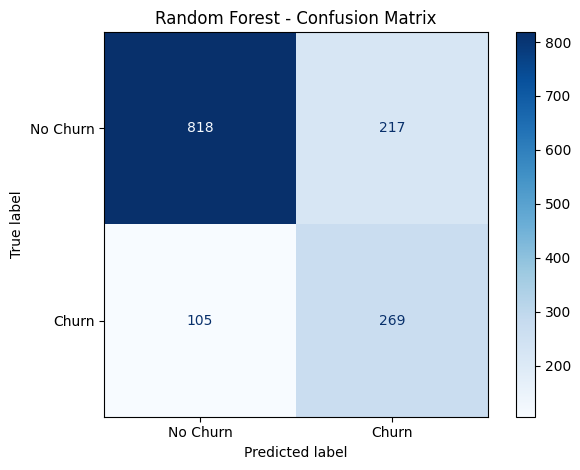

In [55]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=["No", "Yes"],
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


TOP 15 MOST IMPORTANT FEATURES
                            Feature  Importance
                        num__tenure      0.1215
       cat__Contract_Month-to-month      0.1130
                  num__TotalCharges      0.1088
                num__MonthlyCharges      0.0773
             cat__Contract_Two year      0.0590
             cat__OnlineSecurity_No      0.0574
                cat__TechSupport_No      0.0459
   cat__InternetService_Fiber optic      0.0456
cat__PaymentMethod_Electronic check      0.0347
             cat__Contract_One year      0.0190
               cat__OnlineBackup_No      0.0177
           cat__InternetService_DSL      0.0146
           cat__PaperlessBilling_No      0.0136
            cat__OnlineSecurity_Yes      0.0132
          cat__PaperlessBilling_Yes      0.0126


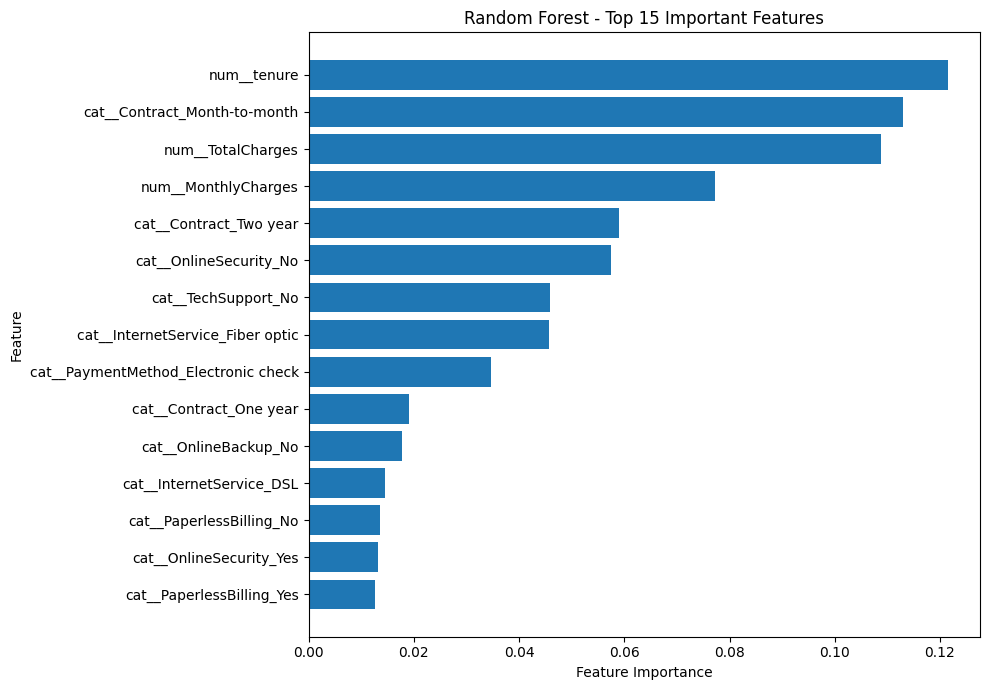

In [56]:

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("TOP 15 MOST IMPORTANT FEATURES")
print(importance_df.head(15).round(4).to_string(index=False))

# Visualize the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 15 Important Features")
plt.tight_layout()
plt.show()

In [57]:

results_dir = (
    "/content/drive/MyDrive/Codveda_ML_Level_1/results"
)

os.makedirs(results_dir, exist_ok=True)

# Save evaluation metrics
rf_metrics = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1_Score": rf_f1,
    "ROC_AUC": rf_auc,
    "Best_CV_F1": rf_search.best_score_
}])

rf_metrics.to_csv(
    os.path.join(results_dir, "random_forest_metrics.csv"),
    index=False
)

# Save feature importance
importance_df.to_csv(
    os.path.join(results_dir, "random_forest_feature_importance.csv"),
    index=False
)

# Save best hyperparameters
pd.DataFrame([rf_search.best_params_]).to_csv(
    os.path.join(results_dir, "random_forest_best_parameters.csv"),
    index=False
)

print("All Random Forest results saved successfully!")
print("Location:", results_dir)


All Random Forest results saved successfully!
Location: /content/drive/MyDrive/Codveda_ML_Level_1/results


In [58]:

import os
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# Create the results folder
results_dir = "/content/drive/MyDrive/Codveda_ML_Level_1/results"
os.makedirs(results_dir, exist_ok=True)

# BASIC TASK 1: Preprocessing summary
preprocessing_summary = pd.DataFrame([
    {"Check": "Original dataset rows", "Result": df.shape[0]},
    {"Check": "Original dataset columns", "Result": df.shape[1]},
    {"Check": "Training customers", "Result": X_train_processed.shape[0]},
    {"Check": "Testing customers", "Result": X_test_processed.shape[0]},
    {"Check": "Processed training features", "Result": X_train_processed.shape[1]},
    {"Check": "Processed test features", "Result": X_test_processed.shape[1]},
    {"Check": "Missing values in processed training data",
     "Result": 0},
    {"Check": "Missing values in processed test data",
     "Result": 0}
])

preprocessing_summary.to_csv(
    os.path.join(results_dir, "basic_task1_preprocessing_summary.csv"),
    index=False
)

# BASIC TASK 3: KNN comparison results
results_df.to_csv(
    os.path.join(results_dir, "basic_task3_knn_k_comparison.csv"),
    index=False
)

# Save baseline KNN metrics (K = 5)
knn_baseline_metrics = pd.DataFrame([{
    "Model": "KNN",
    "K": 5,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, pos_label="Yes", zero_division=0),
    "Recall": recall_score(y_test, y_pred, pos_label="Yes", zero_division=0),
    "F1_Score": f1_score(y_test, y_pred, pos_label="Yes", zero_division=0)
}])

knn_baseline_metrics.to_csv(
    os.path.join(results_dir, "basic_task3_knn_baseline_metrics.csv"),
    index=False
)

# Save baseline confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
).to_csv(
    os.path.join(results_dir, "basic_task3_knn_confusion_matrix.csv")
)

print("Basic Task 1 and Task 3 results saved:")
for filename in [
    "basic_task1_preprocessing_summary.csv",
    "basic_task3_knn_k_comparison.csv",
    "basic_task3_knn_baseline_metrics.csv",
    "basic_task3_knn_confusion_matrix.csv"
]:
    print("-", filename)


Basic Task 1 and Task 3 results saved:
- basic_task1_preprocessing_summary.csv
- basic_task3_knn_k_comparison.csv
- basic_task3_knn_baseline_metrics.csv
- basic_task3_knn_confusion_matrix.csv


In [60]:
import os

readme_path = "/content/drive/MyDrive/Codveda_ML_Level_1/README.md"

print("Exists:", os.path.exists(readme_path))
print("Is directory:", os.path.isdir(readme_path))
print("Is file:", os.path.isfile(readme_path))

Exists: True
Is directory: True
Is file: False


In [61]:
import os

readme_path = (
    "/content/drive/MyDrive/Codveda_ML_Level_1/"
    "README.md/README.md"
)

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README saved successfully!")
print("Location:", readme_path)

README saved successfully!
Location: /content/drive/MyDrive/Codveda_ML_Level_1/README.md/README.md


##Task 2 — SVM Classification(ADVANCED)

In [68]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    ConfusionMatrixDisplay
)

print("SVM libraries imported successfully!")


SVM libraries imported successfully!


In [69]:

svm_models = {
    "Linear SVM": SVC(
        kernel="linear",
        C=1.0,
        probability=True,
        random_state=42
    ),
    "RBF SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    )
}

svm_results = []
trained_svm_models = {}

for name, model in svm_models.items():
    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)
    yes_index = list(model.classes_).index("Yes")
    probabilities = model.predict_proba(X_test_processed)[:, yes_index]

    auc = roc_auc_score(
        (y_test == "Yes").astype(int),
        probabilities
    )

    svm_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "ROC_AUC": auc
    })

    trained_svm_models[name] = model

svm_results_df = pd.DataFrame(svm_results)

print("\nSVM KERNEL COMPARISON")
print(svm_results_df.round(4).to_string(index=False))


Training Linear SVM...
Training RBF SVM...

SVM KERNEL COMPARISON
     Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
Linear SVM    0.7878     0.6176  0.5267    0.5685   0.8246
   RBF SVM    0.7913     0.6418  0.4840    0.5518   0.7902


RBF SVM Classification Report
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



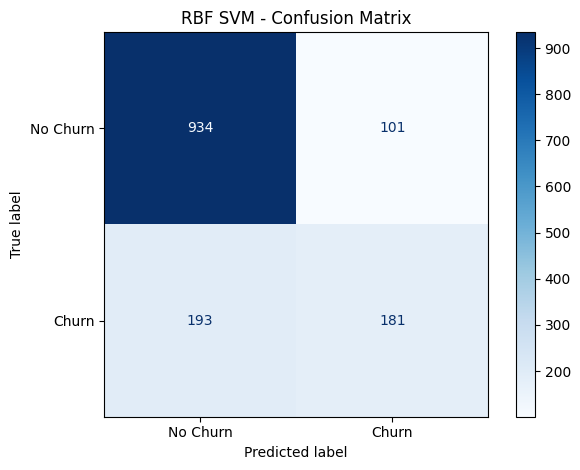

In [70]:

# Use the RBF model for detailed evaluation
best_svm = trained_svm_models["RBF SVM"]

y_pred_svm = best_svm.predict(X_test_processed)

print("RBF SVM Classification Report")
print(classification_report(y_test, y_pred_svm, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    labels=["No", "Yes"],
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("RBF SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


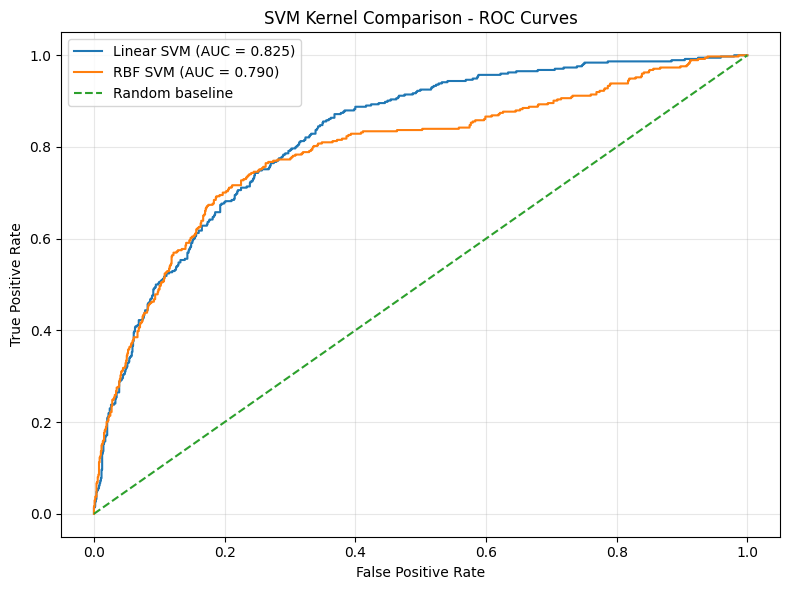

In [71]:

plt.figure(figsize=(8, 6))

for name, model in trained_svm_models.items():
    yes_index = list(model.classes_).index("Yes")
    probabilities = model.predict_proba(X_test_processed)[:, yes_index]

    fpr, tpr, _ = roc_curve(
        (y_test == "Yes").astype(int),
        probabilities
    )

    auc = roc_auc_score(
        (y_test == "Yes").astype(int),
        probabilities
    )

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM Kernel Comparison - ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [72]:

import os

results_dir = (
    "/content/drive/MyDrive/Codveda_ML_Level_1/results"
)
os.makedirs(results_dir, exist_ok=True)

svm_results_df.to_csv(
    os.path.join(results_dir, "advanced_task2_svm_metrics.csv"),
    index=False
)

print("SVM metrics saved successfully!")


SVM metrics saved successfully!
